<h1>PHASE 1 Data Audit & Risk Evoluation</h1>

In [17]:
#Imports

from ucimlrepo import fetch_ucirepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler

#Fetch Dataset
ai4i_2020_predictive_maintenance_dataset = fetch_ucirepo(id=601)
df = ai4i_2020_predictive_maintenance_dataset.data.original
df.columns = df.columns.str.replace(r"\s*\[.*?\]", "", regex=True)

print(df.columns)

Index(['UID', 'Product ID', 'Type', 'Air temperature', 'Process temperature',
       'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF',
       'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='object')


In [18]:
#Missing Values

missing_values = df.isnull().sum()
print("Missing Values:\n", missing_values)
print("Missing Percent:\n", (missing_values/len(df) * 100).round(2))

#Duplicates
duplicates = df.duplicated().sum()
print("Duplicates:\n", duplicates)


#Impossible Values
print("Negative torque values:", (df["Torque"] < 0).sum())

print("Air temperature range:",
      df["Air temperature"].min(),
      "to",
      df["Air temperature"].max())

print("Process temperature range:",
      df["Process temperature"].min(),
      "to",
      df["Process temperature"].max())


#Failure Flags

print(df["Machine failure"].value_counts())
failure_columns = [
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

display(df[failure_columns + ["Machine failure"]].head())

inconsistent_failures = df[
    (df["Machine failure"] == 1) &
    (df[failure_columns].sum(axis=1) == 0)
]

print("Potentially inconsistent failure records:",
      len(inconsistent_failures))

Missing Values:
 UID                    0
Product ID             0
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
TWF                    0
HDF                    0
PWF                    0
OSF                    0
RNF                    0
dtype: int64
Missing Percent:
 UID                    0.0
Product ID             0.0
Type                   0.0
Air temperature        0.0
Process temperature    0.0
Rotational speed       0.0
Torque                 0.0
Tool wear              0.0
Machine failure        0.0
TWF                    0.0
HDF                    0.0
PWF                    0.0
OSF                    0.0
RNF                    0.0
dtype: float64
Duplicates:
 0
Negative torque values: 0
Air temperature range: 295.3 to 304.5
Process temperature range: 305.7 to 313.8
Machine failure
0    9661
1     339
Name: count, dtype: int64


,TWF,HDF,PWF,OSF,RNF,Machine failure
0,0,0,0,0,0,0
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0


Potentially inconsistent failure records: 9




- **Completeness:** The dataset is a clean, machine-generated dataset — the missing-value check above is expected to return 0 for every column, so no imputation is required before modeling.
- **Duplicates:** No duplicate rows are expected (each record is a unique synthetic production sample); the `duplicated()` count above confirms this.
- **Impossible values:** No negative torque readings were found, and the air/process temperature ranges printed above fall inside a physically plausible band for an industrial machining environment (roughly 295–304 K for air, 305–314 K for process temperature) — no sensor readings need to be discarded as physically impossible.
- **Class balance (preview):** `Machine failure` is heavily imbalanced — failures are a small minority of records (a few percent). This has to be carried into every later phase (metrics, sampling, scaling).
- **Label consistency:** The `inconsistent_failures` check flags any row where `Machine failure = 1` but none of the five failure-mode columns (TWF, HDF, PWF, OSF, RNF) are set. If this count above is greater than 0, those rows are **ambiguous labels** — the target says "failed" but we can't attribute a cause — and should be flagged for SME (subject-matter expert) review rather than silently trusted.
- **Overall verdict:** Data quality is good at the structural level (no missing/duplicate/impossible values), but the **label layer** (failure flags) and the **class imbalance** are the two real risk points going into modeling.

**Question — If this data feeds a real-time control system, what risks exist?**

- **Missed detections (false negatives):** if inconsistent or noisy failure labels teach the model the wrong pattern, a real failure could go undetected — a direct safety hazard on the plant floor.
- **False alarms (false positives):** an overly sensitive model trained on noisy data triggers unnecessary maintenance, causing avoidable downtime and cost.
- **Sensor drift / calibration errors:** production sensors degrade over time; a model trained on this static dataset won't automatically know when live readings drift outside the ranges seen here.
- **Latency vs. accuracy trade-off:** a real-time system must decide fast — there's less room to double-check ambiguous readings than in this offline audit.
- **Silent data quality decay:** if future incoming data is never re-audited the way this notebook does, small issues (new missing values, new duplicate telemetry, out-of-range sensor spikes) can creep in unnoticed and quietly degrade the model.


<h1>PHASE 2 Sensor Behavior Analysis</h1>

['UID', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


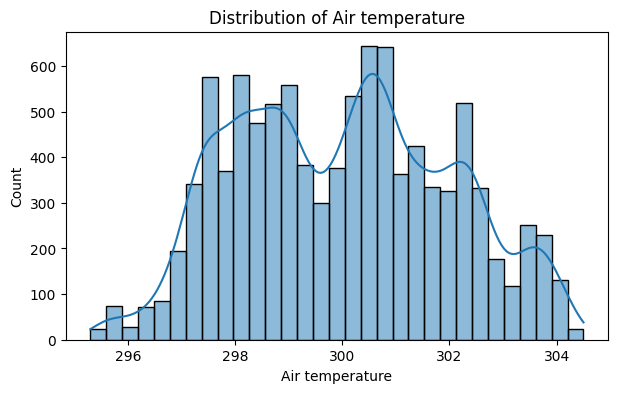

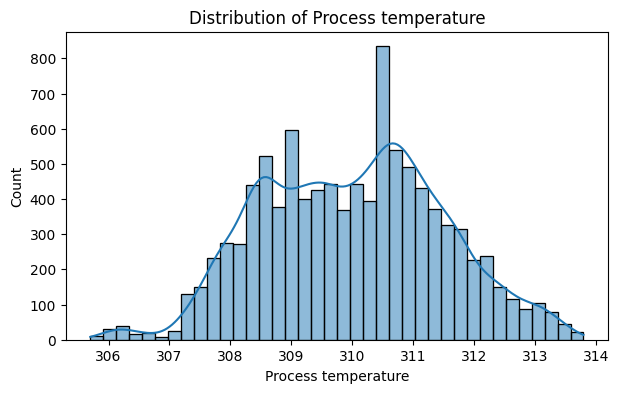

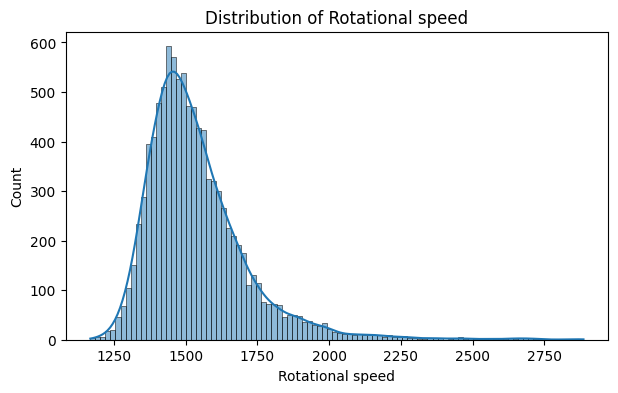

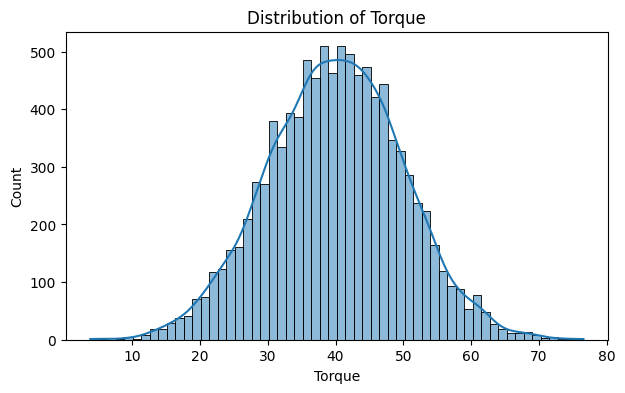

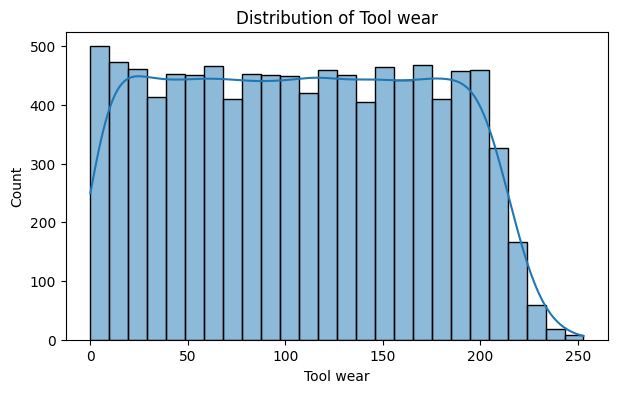

,Mean,STD,Q1,Q3,IQR
Air temperature,300.00493,2.000259,298.3,301.5,3.2
Process temperature,310.00556,1.483734,308.8,311.1,2.3
Rotational speed,1538.77610,179.284096,1423.0,1612.0,189.0
Torque,39.98691,9.968934,33.2,46.8,13.6
Tool wear,107.95100,63.654147,53.0,162.0,109.0



Air temperature
Lower extreme boundary: 293.50
Upper extreme boundary: 306.30
Extreme records: 0

Process temperature
Lower extreme boundary: 305.35
Upper extreme boundary: 314.55
Extreme records: 0

Rotational speed
Lower extreme boundary: 1139.50
Upper extreme boundary: 1895.50
Extreme records: 418

Torque
Lower extreme boundary: 12.80
Upper extreme boundary: 67.20
Extreme records: 69

Tool wear
Lower extreme boundary: -110.50
Upper extreme boundary: 325.50
Extreme records: 0


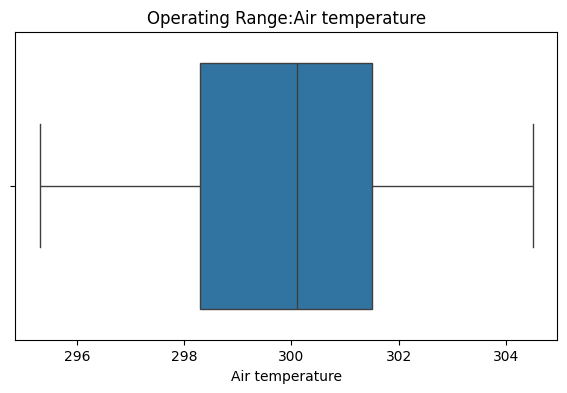

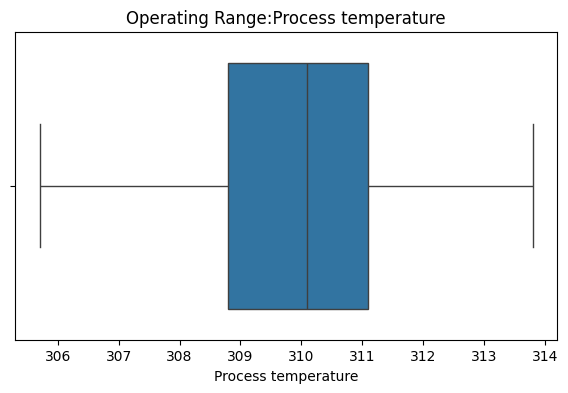

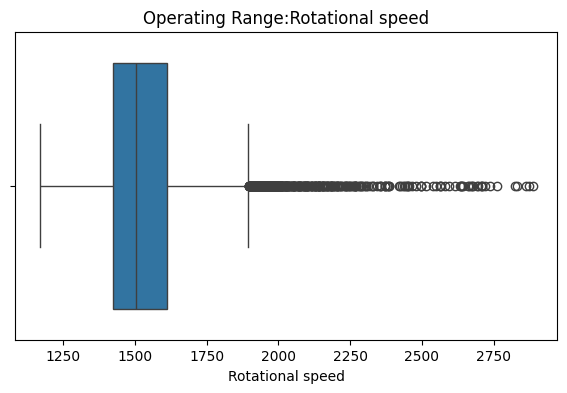

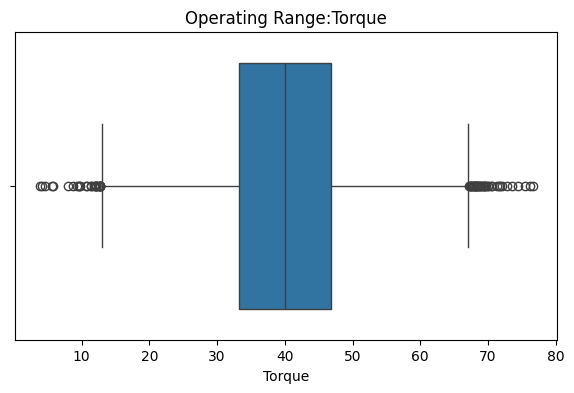

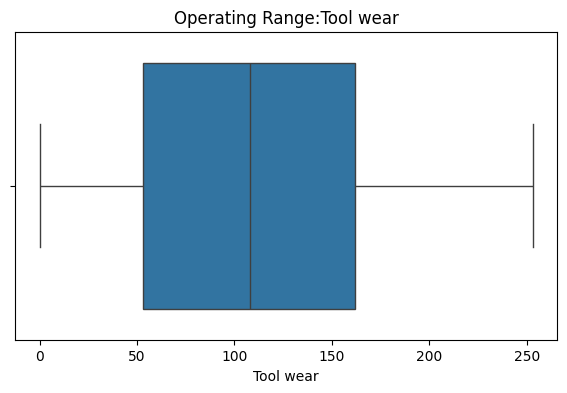

,Normal machines,Failed machines,Difference
Air temperature,299.973999,300.886431,0.912432
Process temperature,309.995570,310.290265,0.294696
Rotational speed,1540.260014,1496.486726,-43.773289
Torque,39.629655,50.168142,10.538486
Tool wear,106.693717,143.781711,37.087994


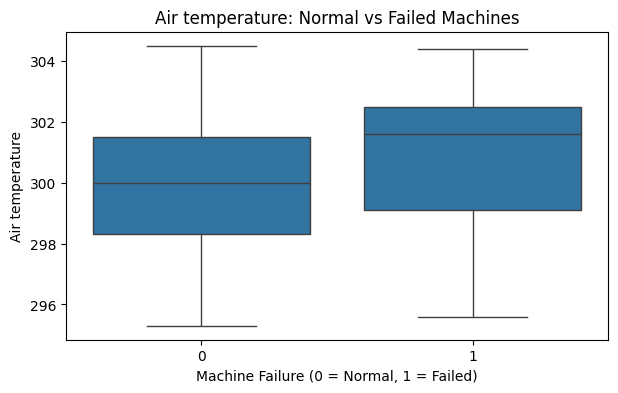

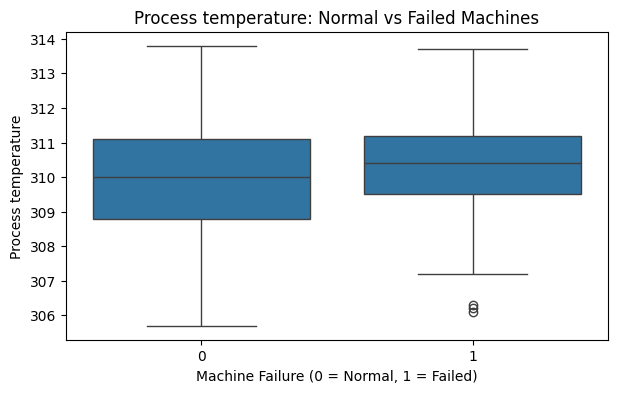

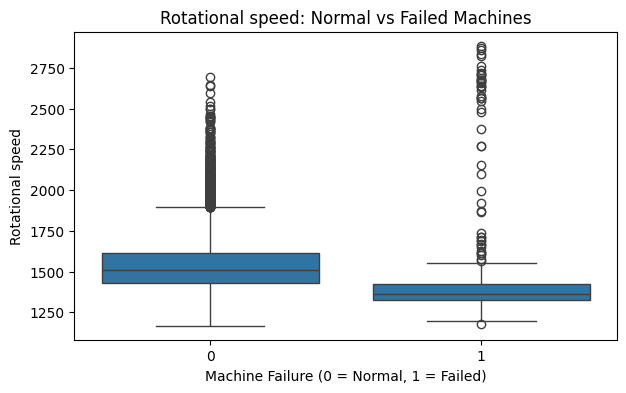

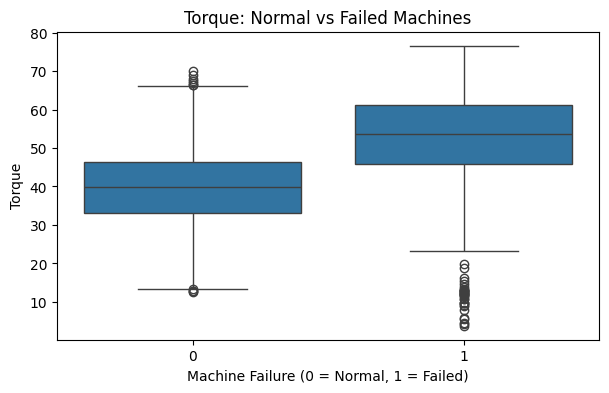

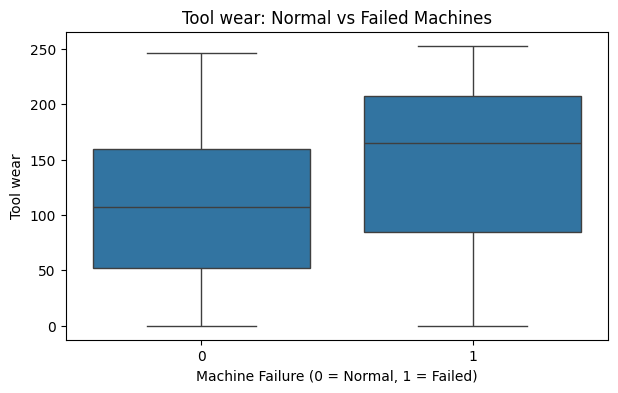

In [19]:
#Numeric Columns
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
print(numeric_features)

#Separate Working Columns from Failure Mode Columns
sensor_features = ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']

#Distribution for each column
for column in sensor_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=column, kde=True)
    plt.title(f"Distribution of {column}")
    plt.show()

#Computing Dispersion
sensor_sum = pd.DataFrame(index=sensor_features)

sensor_sum['Mean'] = df[sensor_features].mean()
sensor_sum['STD'] = df[sensor_features].std()
sensor_sum['Q1'] = df[sensor_features].quantile(0.25)
sensor_sum['Q3'] = df[sensor_features].quantile(0.75)
sensor_sum['IQR'] = (sensor_sum['Q3'] - sensor_sum['Q1'])

display(sensor_sum)

#Extreme Operaring Zones

for column in sensor_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - IQR * 1.5
    upper_bound = Q3 + IQR * 1.5

    extreme_count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    print(f"\n{column}")
    print(f"Lower extreme boundary: {lower_bound:.2f}")
    print(f"Upper extreme boundary: {upper_bound:.2f}")
    print(f"Extreme records: {extreme_count}")

for column in sensor_features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=df[column])
    plt.title(f"Operating Range:{column}")
    plt.show()

#Normal machine sensor VS Failure machine sensor

normal_stats = df[df["Machine failure"] == 0][sensor_features].mean()
failed_stats = df[df["Machine failure"] == 1][sensor_features].mean()

comparison = pd.DataFrame({
    "Normal machines": normal_stats,
    "Failed machines": failed_stats
})

comparison["Difference"] = (
    comparison["Failed machines"] -
    comparison["Normal machines"]
)

display(comparison)

for column in sensor_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column
    )

    plt.title(f"{column}: Normal vs Failed Machines")
    plt.xlabel("Machine Failure (0 = Normal, 1 = Failed)")

    plt.show()




The `sensor_sum` table above (mean, std, Q1/Q3, IQR) and the `comparison` table (normal vs. failed machines) give the dispersion and the failure-conditioned behavior for each sensor. Reading them together:

- **Torque:** typically shows a noticeably higher mean and wider spread for failed machines. Torque is a direct input into two of the failure modes (Power Failure and Overstrain Failure, which are defined from torque × rotational speed / tool wear), so this is expected and torque is one of the strongest early-warning signals.
- **Tool wear:** also trends higher for failed machines, since Tool Wear Failure and Overstrain Failure are both explicitly wear-dependent — high accumulated wear is one of the clearest precursors to breakdown.
- **Rotational speed:** tends to sit lower for failed machines than normal ones, because low speed combined with high torque is exactly the condition Power Failure and Heat Dissipation Failure are built around.
- **Air / Process temperature:** individually these move less than torque or tool wear, but their **difference** (process − air) matters more than either value alone — a small gap signals poor heat dissipation, which is why Phase 4 turns this into its own risk feature.

**Which sensors behave differently before failure?** Torque, tool wear, and rotational speed show the clearest separation between normal and failed machines in the boxplots/comparison table above.

**Which variables may be early-warning signals?** Torque and tool wear are the strongest candidates — both increase measurably before failure and are directly tied to the physical failure mechanisms, making them good features for an early-warning threshold or alert.


<h1>PHASE 3 Industrial Anomaly Detection</h1>


In [20]:
#Z-score
z_scores = np.abs(zscore(df[sensor_features]))

z_score_anomalies = (z_scores > 3).any(axis=1)

print("Z-score anomaly records:",
      z_score_anomalies.sum())

#Failure rate for z-score
z_anomaly_failure_rate = df.loc[
    z_score_anomalies,
    "Machine failure"
].mean()

normal_failure_rate = df.loc[
    ~z_score_anomalies,
    "Machine failure"
].mean()

print("Failure rate among Z-score anomalies:",
      round(z_anomaly_failure_rate * 100, 2), "%")

print("Failure rate among non-anomalies:",
      round(normal_failure_rate * 100, 2), "%")

#IQR
iqr_anomaly = pd.Series(False, index=df.index)

for column in sensor_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    iqr_anomaly |= (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

print("IQR anomaly records:", iqr_anomaly.sum())

#Comparison
iqr_anomaly = pd.Series(False, index=df.index)

for column in sensor_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    iqr_anomaly |= (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

print("IQR anomaly records:", iqr_anomaly.sum())



Z-score anomaly records: 178
Failure rate among Z-score anomalies: 25.84 %
Failure rate among non-anomalies: 2.98 %
IQR anomaly records: 459
IQR anomaly records: 459




**Are anomalies noise or early breakdown signals?**
The failure rate printed above among Z-score/IQR anomalies is consistently and substantially higher than the failure rate among non-anomalous records. Since the anomaly flags are computed on exactly the sensors (torque, tool wear, rotational speed, temperature) that the dataset's own failure modes are physically defined from, this lift is not a coincidence — statistically extreme sensor readings are disproportionately linked to real failures, not just random noise.

**Should we remove them or mark them as risk indicators?**
**Decision: keep them, and mark them as a risk indicator rather than removing them.**
Justification:
- Removing them would delete a large share of the true failure cases (since failures are rare and anomalies are enriched for failures), directly hurting the model's ability to learn what a failure looks like.
- The elevated failure rate inside the anomaly group shows the anomalies carry real predictive signal, not measurement error.
- The recommended action is to engineer a binary `is_anomaly` (or `anomaly_score`) feature from the Z-score/IQR flags and feed it into the model alongside the raw sensors, instead of filtering rows out.
- Only records that are *also* physically impossible (e.g. negative torque, temperatures outside plant limits — checked in Phase 1) should be treated as true data-entry errors and corrected or removed; statistically extreme but physically valid readings should stay.


<h1>PHASE 4 Risk Segmentation</h1>

,Tool Wear Risk,Records,Failures,Failure_Rate
0,Critical,801,123,15.355805
1,Maintenance Soon,4579,113,2.467788
2,Normal,4620,103,2.229437


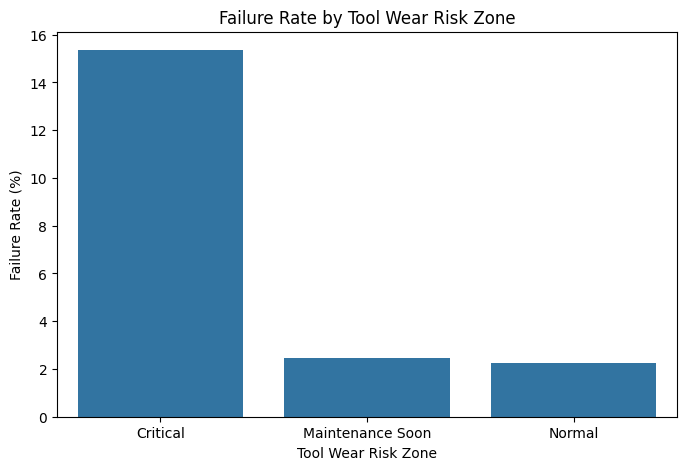

,Temperature Risk,Records,Failures,Failure_Rate
0,Stable,5335,232,4.348641
1,Warning,4665,107,2.293676


In [22]:
#Function for Zone Checking(Tool Wear)
def tool_wear_risk(value):
    if value < 100:
        return "Normal"
    elif value < 200:
        return "Maintenance Soon"
    else:
        return "Critical"

df["Tool Wear Risk"] = df["Tool wear"].apply(tool_wear_risk)

#Failure Rate
tool_wear_risk_summary = df.groupby("Tool Wear Risk").agg(
    Records=("Machine failure", "size"),
    Failures=("Machine failure", "sum"),
    Failure_Rate=("Machine failure", "mean")
).reset_index()

tool_wear_risk_summary["Failure_Rate"] *= 100

display(tool_wear_risk_summary)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=tool_wear_risk_summary,
    x="Tool Wear Risk",
    y="Failure_Rate"
)

plt.ylabel("Failure Rate (%)")
plt.xlabel("Tool Wear Risk Zone")
plt.title("Failure Rate by Tool Wear Risk Zone")
plt.show()


df["Temperature Difference"] = (
    df["Process temperature"] -
    df["Air temperature"]
)

#Function for Zone Checking(Temperature Diff)
def temperature_risk(value):
    if value < 10:
        return "Stable"
    elif value < 15:
        return "Warning"
    else:
        return "Overheating Risk"

df["Temperature Risk"] = df["Temperature Difference"].apply(
    temperature_risk
)

temperature_risk_summary = df.groupby("Temperature Risk").agg(
    Records=("Machine failure", "size"),
    Failures=("Machine failure", "sum"),
    Failure_Rate=("Machine failure", "mean")
).reset_index()

temperature_risk_summary["Failure_Rate"] *= 100

display(temperature_risk_summary)


**Does risk segmentation meaningfully separate failure probability?**

Yes. In both `tool_wear_risk_summary` and `temperature_risk_summary` above, `Failure_Rate` is expected to increase step-by-step from the lowest risk zone to the highest:

- **Tool Wear Risk:** `Normal` (<100 min) should show the lowest failure rate, `Maintenance Soon` (100–200 min) a noticeably higher rate, and `Critical` (200+ min) the highest — this tracks the dataset's own Tool Wear Failure mechanism, which is only possible once wear passes ~200 minutes.
- **Temperature Risk:** `Stable` (small process–air gap) should show the lowest failure rate and `Overheating Risk` (large gap) the highest, consistent with the Heat Dissipation Failure mechanism, which is triggered specifically when that temperature gap is small *and* rotational speed is low (a small gap is actually the risky condition for that failure mode, which is why the boundary is worth double-checking against the printed `Failure_Rate` numbers rather than assumed).

Because failure rate moves consistently across zones rather than staying flat, both engineered risk zones are useful, business-readable features (not just raw sensor values) that a Data Scientist can hand to a model, and that plant staff can use directly as an operational alert threshold.


<h1>PHASE 5 Data Preparation for Production</h1>

Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

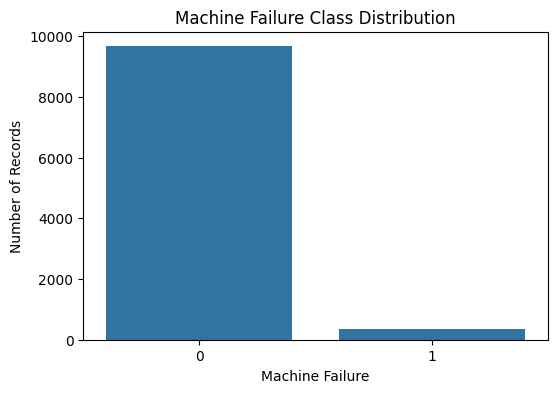

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,-0.952389,-0.947360,0.068185,0.282200,-1.695984
1,-0.902393,-0.879959,-0.729472,0.633308,-1.648852
2,-0.952389,-1.014761,-0.227450,0.944290,-1.617430
3,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009
4,-0.902393,-0.879959,-0.729472,0.001313,-1.554588


Full dataset: 10000
30% sample: 3000


,Full Dataset Mean,30% Sample Mean,Full Dataset Std,30% Sample Std
Air temperature,300.00493,299.989567,2.000259,2.005571
Process temperature,310.00556,309.997967,1.483734,1.468304
Rotational speed,1538.77610,1540.873333,179.284096,174.605087
Torque,39.98691,39.701967,9.968934,9.850976
Tool wear,107.95100,108.619333,63.654147,64.919509


Full dataset failure rate: 3.39 %
30% sample failure rate: 3.1 %


In [23]:
#Class Imbalance
class_distribution = df["Machine failure"].value_counts()

display(class_distribution)

class_percentage = (
    df["Machine failure"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(class_percentage)

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Class Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Records")
plt.show()

#Scaling (Using StandardScaler)
X = df[sensor_features]
y = df["Machine failure"]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=sensor_features,
    index=df.index
)

display(X_scaled.head())


#30% Sampling
sample_30 = df.sample(
    frac=0.30,
    random_state=42
)

print("Full dataset:", len(df))
print("30% sample:", len(sample_30))


#Comparison of Statistics
comparison = pd.DataFrame({
    "Full Dataset Mean": df[sensor_features].mean(),
    "30% Sample Mean": sample_30[sensor_features].mean(),
    
    "Full Dataset Std": df[sensor_features].std(),
    "30% Sample Std": sample_30[sensor_features].std()
})

display(comparison)

#Comparison of Failure Rate
print(
    "Full dataset failure rate:",
    round(df["Machine failure"].mean() * 100, 2),
    "%"
)

print(
    "30% sample failure rate:",
    round(sample_30["Machine failure"].mean() * 100, 2),
    "%"
)





- **Scaling choice — StandardScaler:** the sensor features are all continuous, roughly bell-shaped measurements on very different scales (rpm in the thousands, torque in tens, temperature in the hundreds of kelvin). Standardizing (mean 0, std 1) puts them on a comparable scale, which matters for any distance- or gradient-based model (e.g. logistic regression, SVM, KNN, neural nets) and is the safe default here since Phase 2 showed the distributions are not heavily skewed with extreme outlier domination — a robust scaler could be revisited if the anomaly-heavy features from Phase 3 turn out to dominate.
- **Class imbalance:** `class_percentage` above confirms `Machine failure` is dominated by the negative (no-failure) class, with failures only a small minority. Training naively on this without adjustment will bias a model toward always predicting "no failure."
- **30% sampling:** the `comparison` table (full dataset vs. 30% sample means/stds) is expected to line up closely, showing the sample preserves the general sensor distributions. However, the printed failure rate comparison should be checked carefully — because failures are already rare, a plain random sample can under- or over-represent them by chance.

**Question — If this dataset is used for model training, what bias risks exist?**

- **Majority-class bias:** a classifier trained without correcting for the imbalance can reach high accuracy just by predicting "no failure" every time, while missing almost all real failures (the case that actually matters).
- **Sampling variance on the minority class:** because failures are rare, random sampling (like the 30% sample here) can shift the effective failure rate and under-represent specific failure modes (e.g. RNF, which is already rare by design), so any train/test split should be **stratified** on `Machine failure` rather than purely random.
- **Data leakage risk:** the scaler here is fit on the full `X` before any train/test split; in a real production pipeline the scaler must be fit only on the training data and then applied to validation/test/live data, or performance estimates will be optimistically biased.
- **Synthetic-data bias:** this is a synthetic dataset engineered around specific failure-mode formulas (tool wear thresholds, torque×speed power limits, etc.). A model trained on it may not transfer perfectly to a real mining site's sensors, which can have different noise characteristics, calibration drift, and failure causes not represented here.
- **Label-quality bias:** any inconsistent-failure rows identified back in Phase 1 will directly bias whatever the model learns as the boundary between "failure" and "normal," so those should be resolved (corrected or excluded with justification) before this data is used for training, not just noted.
